In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
import cv2 as cv 
print("import successfully!")

import successfully!


# Step 2: Load the Image

In [3]:
IMAGE_PATH = "My_image.jpg"
image_bgr = cv.imread(IMAGE_PATH)

if image_bgr is None:
    raise FileNotFoundError(f"Image file '{IMAGE_PATH}' not found.")

print("image shape:", image_bgr.shape)
print("image type:", image_bgr.dtype)


image shape: (2268, 4032, 3)
image type: uint8


# Step 3: Inspect the Image

In [4]:
height, width, channels = image_bgr.shape
print(f"Image dimensions: {height} x {width} x {channels}")

cy, cx = height // 2, width // 2
print(f"Top-left pixel [0,0] (B,G,R): {image_bgr[0, 0]}")
print(f"Center pixel [{cy},{cx}] (B,G,R): {image_bgr[cy, cx]}")

print("Global min:", image_bgr.min(), "Global max:", image_bgr.max())
for i, name in enumerate(['Blue', 'Green', 'Red']):
    print(f"{name} channel -> min: {image_bgr[:, :, i].min()}, max: {image_bgr[:, :, i].max()}")

Image dimensions: 2268 x 4032 x 3
Top-left pixel [0,0] (B,G,R): [213 193 175]
Center pixel [1134,2016] (B,G,R): [201 206 205]
Global min: 0 Global max: 255
Blue channel -> min: 0, max: 255
Green channel -> min: 0, max: 255
Red channel -> min: 0, max: 255


# Step 4: Convert Colors and Sparate Channels

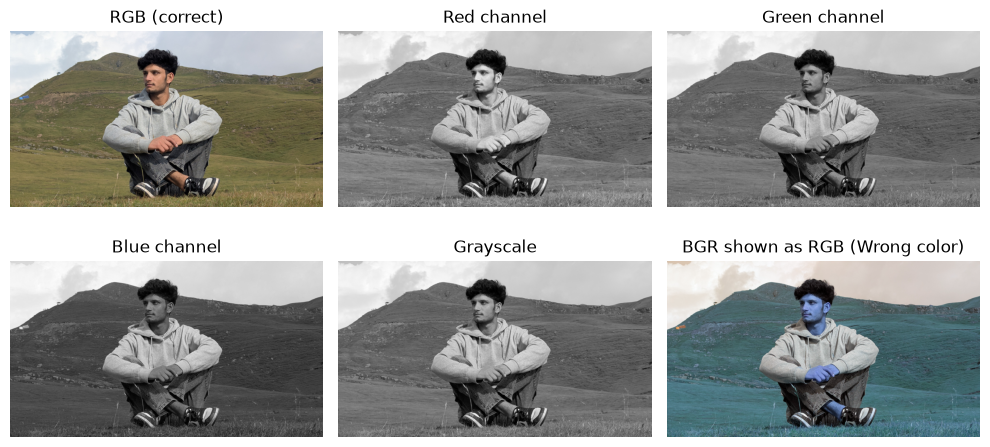

Center pixel RGB: (205, 206, 201) HEX: #cdcec9


In [5]:
image_rgb = cv.cvtColor(image_bgr, cv.COLOR_BGR2RGB)
gray      = cv.cvtColor(image_rgb, cv.COLOR_RGB2GRAY)
R,G,B     = image_rgb[:,:,0], image_rgb[:,:,1], image_rgb[:,:,2]

fig, axes = plt.subplots(2, 3, figsize=(10, 5))
items = [
    (image_rgb, "RGB (correct)",       None),
    (R,         "Red channel",         "gray"),
    (G,         "Green channel",       "gray"),
    (B,         "Blue channel",        "gray"),
    (gray,      "Grayscale",           "gray"),
    (image_bgr, "BGR shown as RGB (Wrong color)", None),
]
for ax, (img, title, cmap) in zip(axes.ravel(), items):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

r, g, b = (int(v) for v in image_rgb[cy, cx])
print("Center pixel RGB:", (r, g, b), "HEX:", f"#{r:02x}{g:02x}{b:02x}")

# Step 5: Crop, Resize, Save

Cropped image shape: (1000, 1000, 3)
Resized image shape: (2000, 2000, 3)


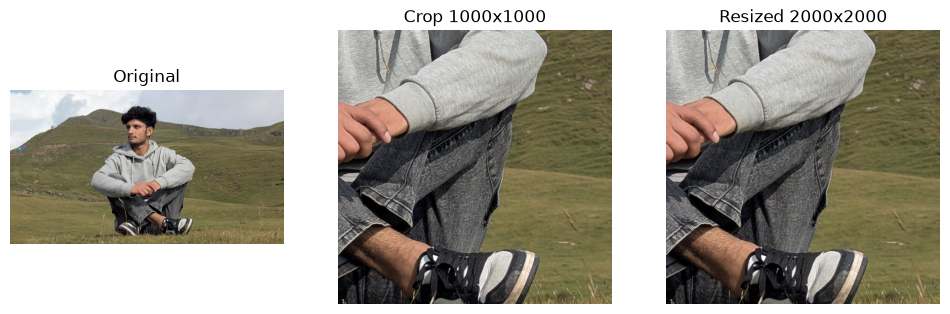

Resized_crop.png saved: True


In [6]:
y_start, x_start = cy - 50, cx - 50
y_end, x_end = y_start + 1000, x_start + 1000

crop = image_rgb[y_start:y_end, x_start:x_end]
print("Cropped image shape:", crop.shape)

resized = cv.resize(crop, (2000, 2000), interpolation=cv.INTER_LINEAR)
print("Resized image shape:", resized.shape)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, img, t in zip(axes, [image_rgb, crop, resized], ["Original", "Crop 1000x1000", "Resized 2000x2000"]):
    ax.imshow(img)
    ax.set_title(t)
    ax.axis('off')

plt.show()

resized_bgr = cv.cvtColor(resized, cv.COLOR_RGB2BGR)
ok = cv.imwrite("resized_crop.png", resized_bgr)
print("Resized_crop.png saved:", ok)

# Step 6: Create a Histogram


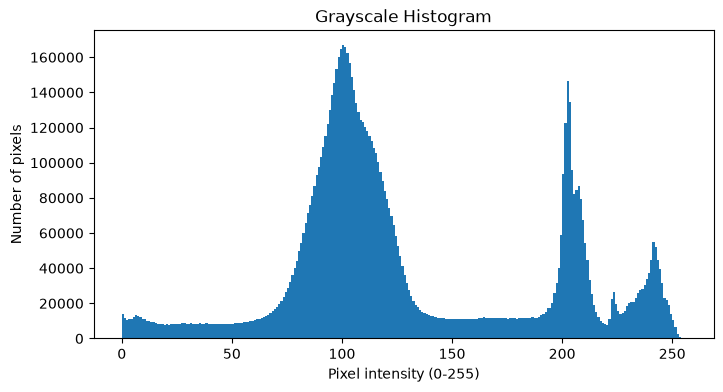

Mean gray value: 129.7


In [7]:
plt.figure(figsize=(8, 4))
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title("Grayscale Histogram")
plt.xlabel("Pixel intensity (0-255)")
plt.ylabel("Number of pixels")
plt.savefig("grayscale_histogram.png")
plt.show()

print("Mean gray value:", round(float(gray.mean()), 1))

#### The histogram shows that most pixels are concentrated in one large peak around intensity 100, mainly between 70 and 135, so the image is dominated by mid-tone gray values. A smaller group of bright pixels appears near 200 and 240, while very few pixels are close to black (0–50). Overall, the image is mainly balanced, leaning slightly toward darker mid-tones, with a mean intensity of about 129.7 and some bright highlights.

# Step 7: Bit depth

### Difference Between Resolustion and Bit Depth 
Resolution is the number of pixels in an image, while bit depth is the number of intensity levels each pixel can have.

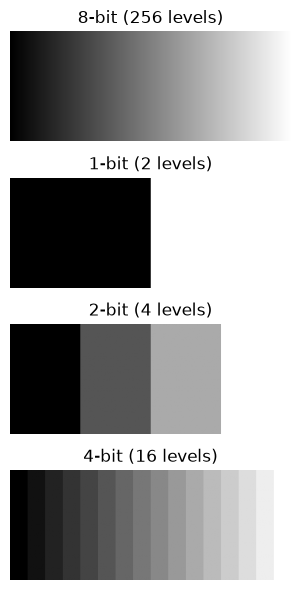

8-bit (256 levels) unique values: 256
1-bit (2 levels) unique values: 2
2-bit (4 levels) unique values: 4
4-bit (16 levels) unique values: 16


In [10]:
gradient = np.tile(np.arange(256, dtype=np.uint8), (100, 1))

def quantize(img, bits):
    levels = 2 ** bits
    step = 256 // levels
    return ((img // step) * (255 // (levels - 1))).astype(np.uint8)

versions = [(gradient, "8-bit (256 levels)")]
for k in (1, 2, 4):
    versions.append((quantize(gradient, k), f"{k}-bit ({2**k} levels)"))

fig, axes = plt.subplots(4, 1, figsize=(8, 6))
for ax, (img, t) in zip(axes, versions):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis("off")
plt.tight_layout()
plt.show()

for img, t in versions:
    print(t, "unique values:", len(np.unique(img)))